In [1]:
print("Hello World")

Hello World


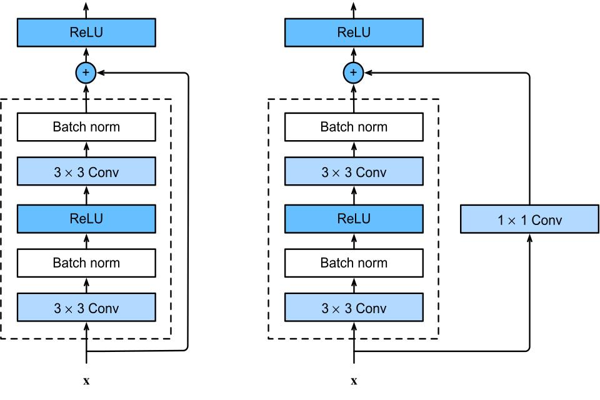

In [2]:
from PIL import Image
img1 = Image.open("res-block.jpg")
resized_img = img1.resize(size=(600,400))
resized_img

In [3]:
from typing import Any

import torch 
import torch.nn as nn

# Single Res Block of the resnet architecture
class ResBlock(nn.Module):

    expansion = 1

    def __init__(self, in_channels, out_channels, stride = 1 ) -> None:
        super().__init__()

        # First Convolution

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        # second convolution

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)


        # out relu
        self.relu = nn.ReLU(inplace=True)

        # skip connection
        self.skip = nn.Sequential()

        if stride != 1 or in_channels != out_channels:
            self.skip = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):

        identity = self.skip(x) # preserves the original input before the res block (so we can add it after processing)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)


        out += identity # adding both the input before the res block (through skip connection) and res block

        out = self.relu(out)

        return out

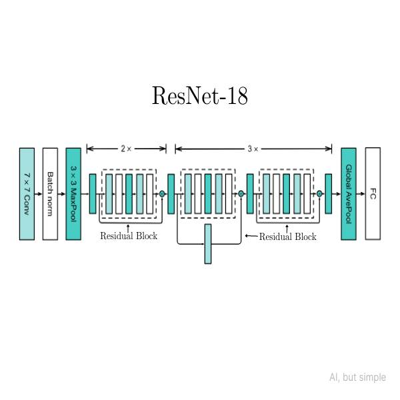

In [4]:
img2 = Image.open("resnet18-architecure.jpg")
resized_img = img2.resize(size=(400,400))
resized_img

In [5]:
# implementing above resnet architecture 

from typing import Any


class ResNet(nn.Module):
    def __init__(self, block, num_blocks, num_classes = 5) -> None:
        super().__init__()


        self.in_channels = 64

        # initial conv

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(64) # out -> 64 channels
        self.relu = nn.ReLU(inplace=True)

        self.maxpool = nn.MaxPool2d(
            kernel_size=3,
            stride=2,
            padding=1
        )

        # Adding Residual Blocks / Layers

        self.layer1 = self.make_layer(block, 64, num_blocks[0], stride = 1)
        self.layer2 = self.make_layer(block, 128, num_blocks[1], stride = 2)
        self.layer3 = self.make_layer(block, 256, num_blocks[2], stride = 2)
        self.layer4 = self.make_layer(block, 512, num_blocks[3], stride = 2)

        # classifier
        self.avgpool = nn.AdaptiveAvgPool2d((1,1))

        self.fc = nn.Linear(512 * block.expansion, num_classes)

    def make_layer(self, block, out_channels, num_blocks, stride):

        strides = [stride] + [1] * (num_blocks - 1)

        layers = []

        for stride in strides:
            layers.append(
                block(self.in_channels, out_channels, stride)
            )

            self.in_channels = out_channels * block.expansion

        return nn.Sequential(*layers)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)


        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)

        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x


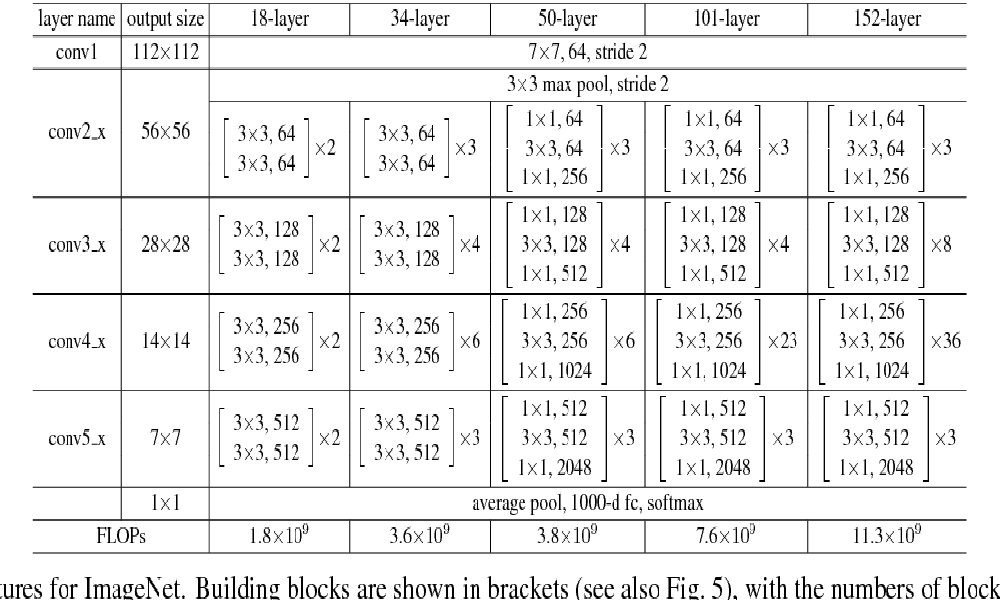

In [6]:
img3 = Image.open("resnet.png")
resized_img = img3.resize(size=(1000,600))
resized_img

In [7]:
# ResNet18

def ResNet18(num_classes = 5):

    return ResNet(
        ResBlock,
        [2, 2, 2, 2], # it represents the number of res blocks in each four stages
        num_classes
    )

In [8]:
# model initialization
model = ResNet18(num_classes=5)

In [9]:
from pathlib import Path

path = Path("C:/MachineLearning/Paper Implementation/VGGNet/flower_dataset")
print(path)

C:\MachineLearning\Paper Implementation\VGGNet\flower_dataset


In [10]:
# transforming the dataset into standard format
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [11]:
# create datasets
train_dataset = datasets.ImageFolder(root="C:/MachineLearning/Paper Implementation/VGGNet/flower_dataset/train", transform=train_transform)
val_dataset = datasets.ImageFolder(root="C:/MachineLearning/Paper Implementation/VGGNet/flower_dataset/val", transform=test_transform)
test_dataset = datasets.ImageFolder(root="C:/MachineLearning/Paper Implementation/VGGNet/flower_dataset/test", transform=test_transform)

In [12]:
# create data loader

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

In [13]:
print("Classes:", train_dataset.classes)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Training images: 3019
Validation images: 644
Testing images: 654


In [14]:
# training config
import torch.optim as optim
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01,
    # weight_decay=0.0005
)

In [15]:
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

Total parameters: 11,179,077


In [16]:
# traning code

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

import time
import torch

EPOCHS = 5

for epoch in range(EPOCHS):

    start_time = time.time()

    # ================= TRAINING =================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Track accuracy
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # ================= VALIDATION =================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # ================= EPOCH SUMMARY =================

    epoch_time = time.time() - start_time

    current_lr = optimizer.param_groups[0]['lr']

    
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_accuracy)

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print("-" * 45)

    print(f"Training Loss:      {train_loss:.4f}")
    print(f"Training Accuracy:  {train_accuracy:.2f}%")

    print(f"Validation Loss:    {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    print(f"Learning Rate:      {current_lr:.6f}")
    print(f"Epoch Time:         {epoch_time:.2f}s")

    print("-" * 45)


Epoch [1/5]
---------------------------------------------
Training Loss:      1.6766
Training Accuracy:  25.14%
Validation Loss:    1.4982
Validation Accuracy: 31.37%
Learning Rate:      0.010000
Epoch Time:         21.20s
---------------------------------------------

Epoch [2/5]
---------------------------------------------
Training Loss:      1.5144
Training Accuracy:  31.43%
Validation Loss:    1.3625
Validation Accuracy: 41.93%
Learning Rate:      0.010000
Epoch Time:         24.52s
---------------------------------------------

Epoch [3/5]
---------------------------------------------
Training Loss:      1.2862
Training Accuracy:  46.27%
Validation Loss:    1.2498
Validation Accuracy: 53.57%
Learning Rate:      0.010000
Epoch Time:         24.65s
---------------------------------------------

Epoch [4/5]
---------------------------------------------
Training Loss:      1.1331
Training Accuracy:  53.33%
Validation Loss:    1.2375
Validation Accuracy: 54.19%
Learning Rate:      0.

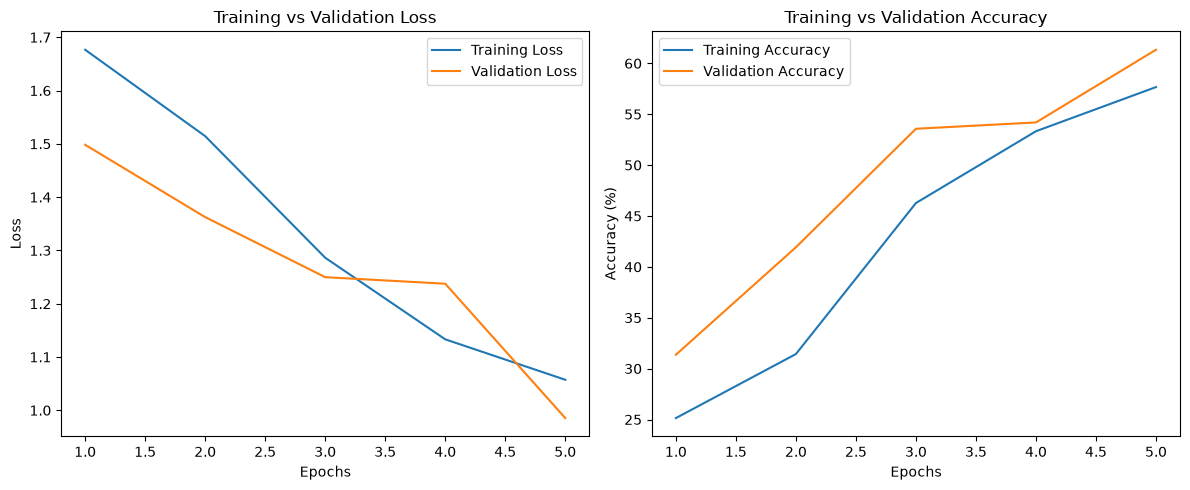

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

# accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Training Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
print("Hello World")

Hello World
